In [1]:
""" Importing required modules """
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from mpl_toolkits.mplot3d import Axes3D
#np.random.seed(0)

In [2]:
""" Initialization of required parameters which have constant values """
N = 5000                                 # Population size
T = 500                                   # Time interval 
NN = np.arange(0, N)                      # Population size in array format (for plotting purposes)
TT = np.arange(0, T)                      # Time interval in array format (for plotting purposes)
P_r = 0.2                                 # Probability that an infected individual is cured  
I_mf = 200                                # A constant increment in immunity whenever a person is cured of infection. (Units = EU)
I_sce = 20                                # A constant level of exposure that ensures subclinical exposure induced immunity with a probability 0.5. (Units = EU)
I_d = 3                                   # A small decrement by which immunity decreases every time unit if not exposed or infected. (Units = Eu)
I_c = 30                                  # Constant Immunity increase due to cross-immunity
a = 2                                     # Parameter deciding the sharpness of the sigmoid relationship 
r = 0.1                                   # Restriction parameter
P_c = 0.1*r                               # Cross immunity parameter
I_cmax = 30*r                             # Maximum number of infective patients with which a normal person can come in contact 
K = 2500                                  # Half-saturation constant of the equation.

In [3]:
# Creating empty 2D array of P values. This array would represent the modified probability of infection for each individual with respect to time.
Pone = np.zeros((N, T))
# Creating empty 2D array of P values. This array would represent the modified probability of infection for each individual with respect to time.
Ptwo = np.zeros((N, T))
# Creating empty 2D array of P_inf(i,t) values. This array would represent the probability of infection for each individual with respect to time.
P_inf = np.zeros((N, T))
# Creating zeros 2D array of P_sce(i,t) values. This array would represent the probability of sub-clinical exposure for each individual with respect to time.
P_sce = np.empty((N, T))
# Creating 2D array of ID_50(i,t) values and assigning values from the standard normal distribution. This array would represent the time evolution of the immunity of each of the individuals with respect to time.
ID_50 = np.zeros((N, 1))                              
# Creating array of E(i,0) values and assigning values from the normal distribution with mean = 70, sd = 30 (for t = 0 case). This array represents the expose bias of each of the individuals at initial time.
E = np.zeros((N, 1))
# Creating array of S(i,t) values. These are the infective states of the individuals with respect to time.
S = np.zeros((N, 1))
# Creating Array which will show the time evolution of I (Total infective state of the population)  
I = np.zeros((T,1))   
# Creating array of SCE_50(i,0) values and assigning values from the normal distribution. This array represents the constant level of exposure of each of the individuals at initial time.
SCE_50 = np.zeros((N, 1))

for j in range(N):
    x1 = np.random.choice(np.arange(0, 2), p=[0.95, 0.05])
    S[j, 0] = x1  
    x2 = round(np.random.normal(20*r, 0.01), 3)
    if (x2 < 0):
        x2 = 0.0001
        E[j, 0] = x2
    else: 
        E[j, 0] = x2
    x3 = round(np.random.normal(100, 30), 3)
    if (x3 < 0):
        x3 = 0.0001
        ID_50[j, 0] = x3
    else:
        ID_50[j, 0] = x3
    x4 = round(np.random.normal(20, 5), 3)
    if (x4 < 0):
        x4 = 0.0001
        SCE_50[j, 0] = x4
    else:
        SCE_50[j, 0] = x4
    
print('Top to bottom - Individuals (0 to N) \nLeft to right - Time steps (0 to T) \nFirst column contains the values for T = 0 \n')
print("1. Initial State of the individuals in the population -- S(i,0):")
print(S)
print("\n 2. Initial expose bias of the individuals in the population -- E(i,0):")
print(E)
print("\n 3. Initial distribution of population immunity levels -- ID_50(i,0):")
print(ID_50)

Top to bottom - Individuals (0 to N) 
Left to right - Time steps (0 to T) 
First column contains the values for T = 0 

1. Initial State of the individuals in the population -- S(i,0):
[[0.]
 [0.]
 [0.]
 ...
 [0.]
 [0.]
 [1.]]

 2. Initial expose bias of the individuals in the population -- E(i,0):
[[1.996]
 [2.004]
 [1.999]
 ...
 [2.012]
 [1.999]
 [1.982]]

 3. Initial distribution of population immunity levels -- ID_50(i,0):
[[140.781]
 [ 10.925]
 [110.056]
 ...
 [ 83.317]
 [ 83.432]
 [101.759]]


In [4]:
X = np.zeros(T)
for t in range(T):
		P_inf_temp = np.zeros((N,))
		P_sce_temp = np.zeros((N,))
		P1_temp = np.zeros((N,))
		P2_temp = np.zeros((N,))
		S_temp = np.zeros((N, 1))
		ID_50_temp = np.zeros((N, 1))
		I_trans_temp = np.zeros((N, 1))
		I[t] = np.sum(S[:,-1])
		for n in range(N):
			I_trans_temp[n] = (I_cmax * I[t])/(K + I[t])
			P_inf_temp[n] = (E[n][0])**a / ((ID_50[n][-1]**a) + (E[n][0]**a))
			P1_temp[n] = 1-((1-P_inf_temp[n])**(I_trans_temp[n]))
			P_sce_temp[n] = (E[n][0])**a / ((SCE_50[n][0]**a) + (E[n][0])**a)
			P2_temp[n] = 1-((1-P_sce_temp[n])**(I_trans_temp[n]))
			# Condition to be imposed when S(t) = 1
			if S[n][-1] == 1:
				x4 = round(np.random.random(), 3)
				if x4 < P_r:
					S_temp[n] = 0
					ID_50_temp[n] = ID_50[n][-1] + I_mf
				else:
					S_temp[n] = 1
					x5 = round(np.random.random(), 3)
					if x5 < P1_temp[n]:
						S_temp[n] = 1
						ID_50_temp[n] = ID_50[n][-1]
					else:
						S_temp[n] = 0
						x6 = round(np.random.random(), 3)
						if x6 < P2_temp[n]:
							ID_50_temp[n] = ID_50[n][-1] + I_sce
						else:
							if (ID_50[n][-1] - I_d < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d
			# Condition to be imposed when S(t) = 0
			else:
				x7 = round(np.random.random(), 3)
				if x7 < P1_temp[n]:
					S_temp[n] = 1
					ID_50_temp[n] = ID_50[n][-1]
				else:
					S_temp[n] = 0
					x8 = round(np.random.random(), 3)
					if x8 < P2_temp[n]:
						x9 = round(np.random.random(), 3)
						if x9 < P_c:
							ID_50_temp[n] = ID_50[n][-1] + I_sce + I_c
						else:
							ID_50_temp[n] = ID_50[n][-1] + I_sce	
					else:
						x9 = round(np.random.random(), 3)
						if x9 < P_c:
							if (ID_50[n][-1] - I_d - I_c < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d + I_c
						else:
							if (ID_50[n][-1] - I_d < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d
		ID_50 = np.hstack((ID_50, ID_50_temp))
		S = np.hstack((S, S_temp))
		P_inf[:,t] = P_inf_temp
		P_sce[:,t] = P_sce_temp
		Pone[:,t] = P1_temp
		Ptwo[:,t] = P2_temp
		x = np.mean(ID_50[:,t])
		X[t] = x
		#print('\n')
		#print("Infective state of the population:")
		#print(I[t])
		#print("Altered state of the population:")
		#print(S)
np.savetxt('ID_50 (0.0, 20*0.0).csv', ID_50, delimiter=',', fmt='%s')
np.savetxt('Infection state (0.0, 20*0.0).csv', I, delimiter=',', fmt='%s')
np.savetxt('Mean ID_50 (0.0, 20*0.0).csv', X, delimiter=',', fmt='%s')
print("\nOverall trend:")
np.set_printoptions(suppress=True)
print(I.reshape(1,T))
print("\nMean Immunity levels:")
np.set_printoptions(suppress=True)
print(X)


Overall trend:
[[256.   7.   3.  10.  16.  20.  15.  16.  14.  24.  27.  43.  55.  66.
   84.  92. 117. 144. 170. 186. 201. 243. 279. 330. 365. 406. 454. 494.
  510. 587. 631. 624. 657. 655. 667. 712. 726. 735. 739. 727. 696. 706.
  684. 655. 649. 628. 575. 542. 513. 504. 492. 456. 430. 432. 394. 366.
  336. 304. 283. 256. 239. 225. 217. 192. 168. 157. 132. 125. 115. 109.
  104.  82.  73.  71.  65.  59.  57.  45.  47.  39.  41.  40.  46.  49.
   60.  71.  71.  71.  79.  82.  83.  94. 119. 146. 156. 182. 220. 217.
  229. 266. 286. 296. 359. 378. 383. 422. 461. 470. 500. 517. 527. 539.
  551. 545. 563. 577. 566. 559. 548. 556. 544. 542. 539. 516. 502. 506.
  485. 480. 460. 448. 440. 429. 391. 388. 365. 353. 327. 306. 300. 293.
  276. 248. 240. 238. 217. 205. 193. 202. 182. 166. 156. 150. 137. 123.
  137. 126. 129. 126. 132. 118. 104. 112. 117. 120. 124. 118. 129. 144.
  148. 158. 170. 186. 218. 229. 239. 266. 265. 280. 289. 294. 329. 328.
  330. 338. 360. 368. 402. 417. 426. 436. 423. 4

In [5]:
print(P_inf.shape)
print(P_sce.shape)
print(S.shape)
print(ID_50.shape)
print(I.shape)

(5000, 500)
(5000, 500)
(5000, 501)
(5000, 501)
(500, 1)


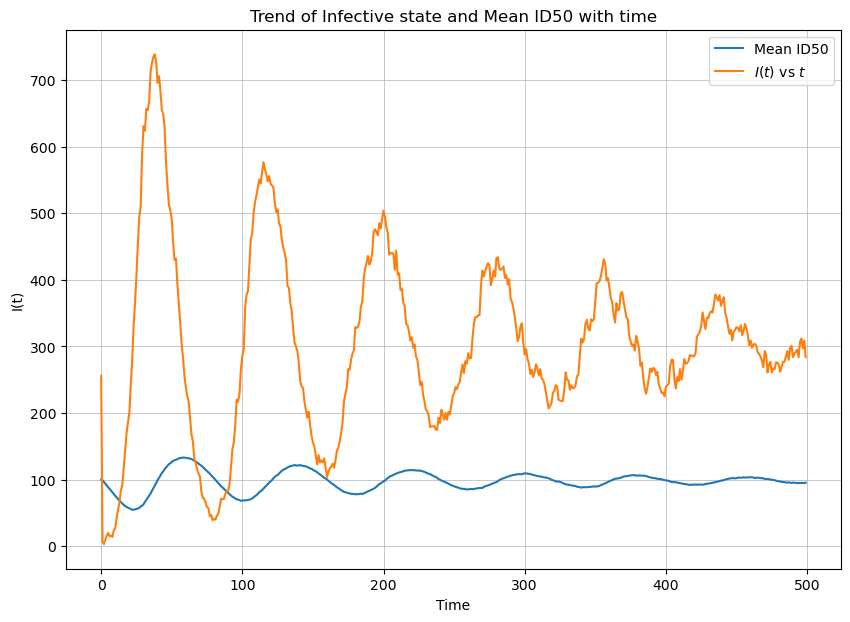

In [6]:
plt.figure(figsize=(10, 7))
X = np.zeros(T)
for t in range(T):
    x = np.mean(ID_50[:,t])
    X[t] = x
plt.plot(TT, X)
plt.plot(TT, I)
plt.title("Trend of Infective state and Mean ID50 with time")
plt.xlabel("Time")
plt.ylabel("I(t)")
plt.legend(["Mean ID50", "$I(t)$ vs $t$"])
plt.grid(linewidth=0.5)
plt.show()

<Figure size 1000x700 with 0 Axes>

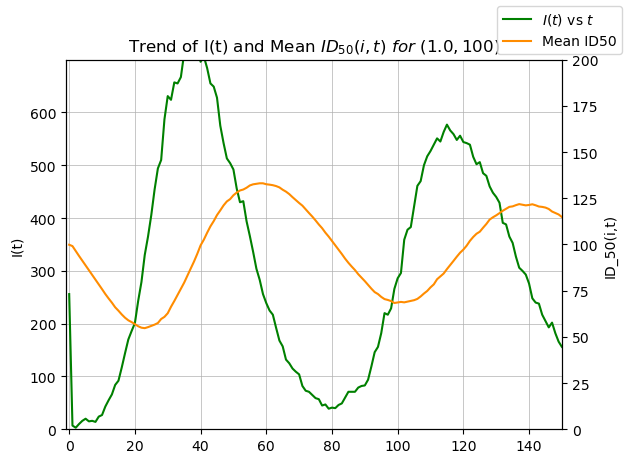

In [7]:
plt.figure(figsize=(10, 7))
X = np.zeros(T)
for t in range(T):
    x = np.mean(ID_50[:,t])
    X[t] = x
fig, ax2 = plt.subplots()
ax1 = ax2.twinx()
ax1.plot(TT, X, color = 'darkorange', label = 'Mean ID50')
ax2.plot(TT, I, color = 'green', label = '$I(t)$ vs $t$')
ax1.set_xlabel('Time')
ax1.set_ylabel('ID_50(i,t)')
ax2.set_ylabel('I(t)')
# Adjust axis limits based on estimates from abve graph
ax1.set(xlim =(-1, 150), ylim =(0, 200), autoscale_on = False)   
ax2.set(xlim =(-1, 150), ylim =(0, 700), autoscale_on = False)
ax2.set_yticks(range(0, 700, 100))
ax2.grid(linestyle='-', linewidth=0.5)
fig.legend(loc='upper right')
ax1.title.set_text('Trend of I(t) and Mean $ID_{50}(i,t) \ for \ (1.0, 100)$')
plt.show()

63
81
72
113
53
2


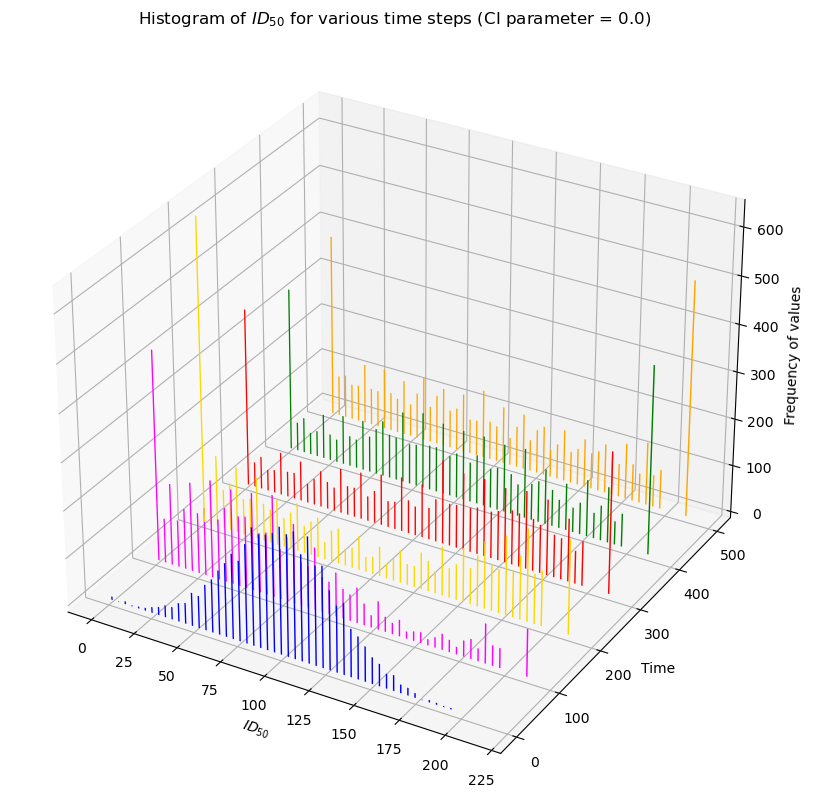

In [8]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
nbins = 50
color = ['orange','green', 'red', 'gold', 'magenta', 'blue']
time_step = [500, 400, 300, 200, 100, 0]
for c, t in zip(color, time_step):
    arr = ID_50[:, t]
    thresh = 200
    true_vals = arr > thresh
    true_sum = np.sum(true_vals)
    false_vals = np.array([i for i in arr if i < thresh])
    hist, xbins = np.histogram(false_vals, bins=nbins)
    new_hist = np.append(hist, t)
    new_bins = np.append(xbins, 225)
    xs = (new_bins[:-1] + new_bins[1:])/2
    ax.bar(xs, new_hist, zs=t, zdir='y', color=c, alpha=1.0)
    ax.title.set_text('Histogram of $ID_{50}$ for various time steps (CI parameter = 0.0)')
    plt.xticks(range(0, 250, 25))
    #labels = ('0', '25', '50', '75', '100', '125', '150', '175', '200', '200')
    #plt.xticks(labels)
    ax.set_xlabel('$ID_{50}$')
    ax.set_ylabel('Time')
    ax.set_zlabel('Frequency of values')
    print(true_sum)
plt.show()


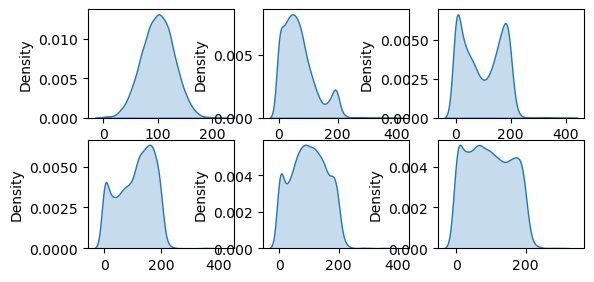

In [9]:
#fig = plt.figure(figsize=(15, 15))
fig = plt.figure()
ax = fig.add_subplot(3, 3, 1)
sns.kdeplot(ID_50[:, 0], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 2)
sns.kdeplot(ID_50[:, 100], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 3)
sns.kdeplot(ID_50[:, 200], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 4)
sns.kdeplot(ID_50[:, 300], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 5)
sns.kdeplot(ID_50[:, 400], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 6)
sns.kdeplot(ID_50[:, 500], fill=True, ax = ax)
plt.show()

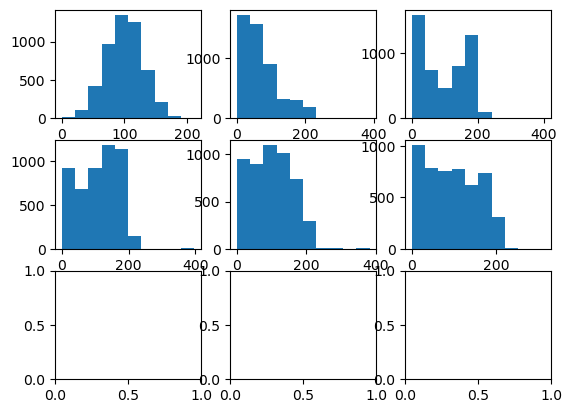

In [10]:
f, ax = plt.subplots(3, 3)
ax[0, 0].hist(ID_50[:, 0])
ax[0, 1].hist(ID_50[:, 100])
ax[0, 2].hist(ID_50[:, 200])
ax[1, 0].hist(ID_50[:, 300])
ax[1, 1].hist(ID_50[:, 400])
ax[1, 2].hist(ID_50[:, 500])
plt.show()

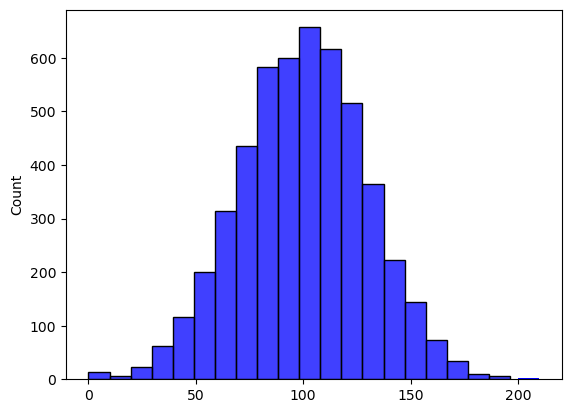

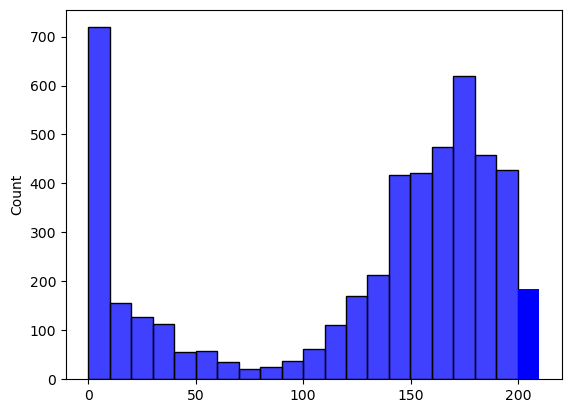

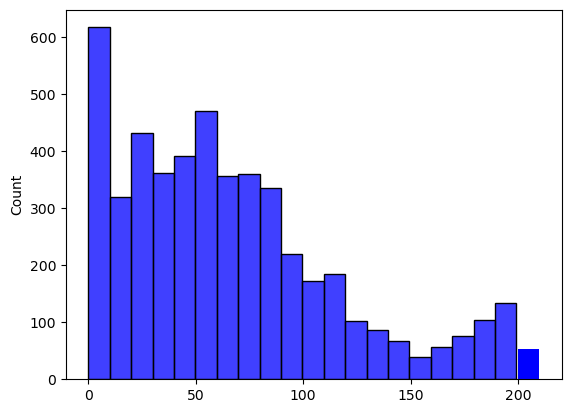

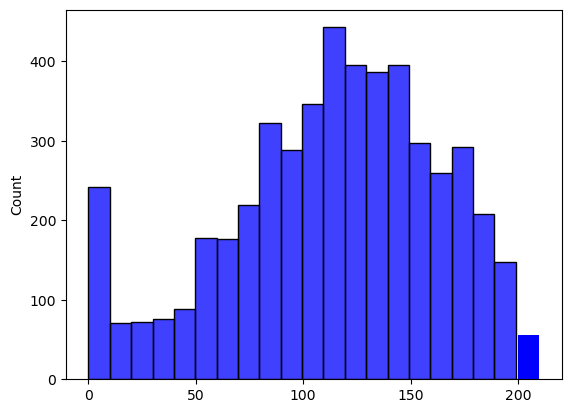

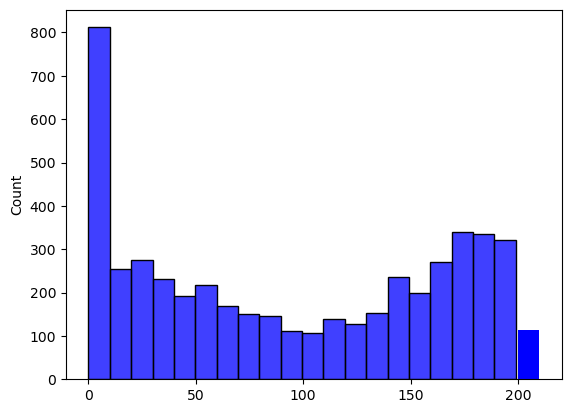

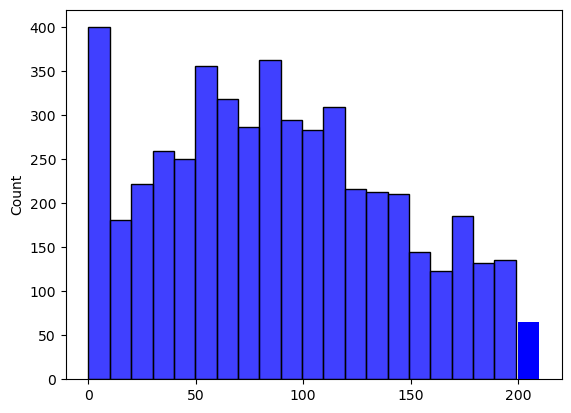

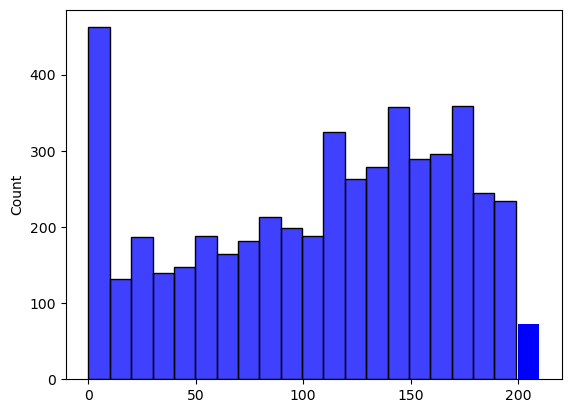

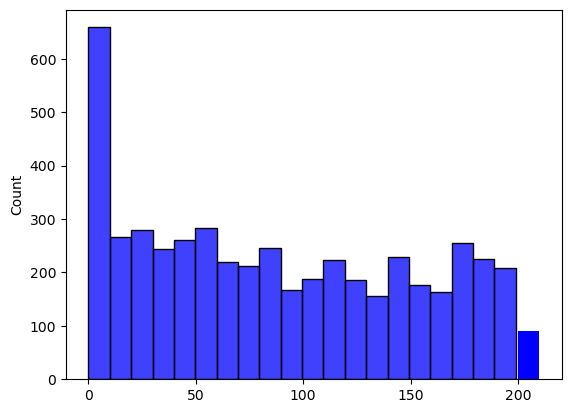

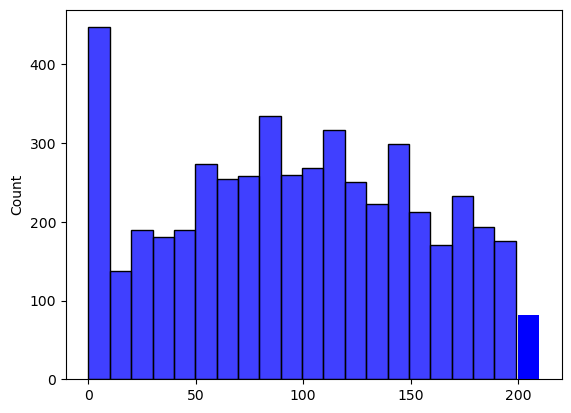

In [11]:
t = 0
n = 9           # Number of time steps for which histogram is to be plotted (t = 0 included)
#T = 320        # To be defined in accordance with the value at the beginning of the program
x = 50          # Increment of time steps. x = T/(n-1) is to be followed
bins = 20
for i in range(n):
    arr = ID_50[:, t]
    thresh = 200
    true_vals = arr > thresh
    true_sum = np.sum(true_vals)
    false_vals = np.array([i for i in arr if i < thresh])
    sns.histplot(false_vals, bins=bins, color='b')
    #plt.ylim(0, 700)
    plt.bar([205], [true_sum], width=10, color='b')
    plt.show()
    t += x